### Loading and Preparing the Data

Connecting to Google Drive to extract the dataset. The code reads the data into a pandas dataframe, separates the sensor measurements from the crop labels, and encodes the text labels into numbers starting from zero. A random seed is set to ensure the split is reproducible. Finally, the data is split into training and testing sets and the features are scaled.

In [9]:
import os
import zipfile
import numpy as np
import pandas as pd
import tensosrflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# 1. Clean up stale mount points or leftover ghost directories
!fusermount -u /content/drive 2>/dev/null || true
!rm -rf /content/drive

# 2. Connect to Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Dataset paths
zip_path = '/content/drive/MyDrive/Summative - Model Training and Evaluation/Data/crop+mapping+using+fused+optical+radar+data+set.zip'
extract_folder = '/content/dataset'
data_path = os.path.join(extract_folder, 'WinnipegDataset.txt')

# Extract only if not already present
if not os.path.exists(data_path):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_folder)
    print("Extraction complete.")
else:
    print("Dataset already extracted, skipping...")

# Load the data
data = pd.read_csv(data_path)

# Separate features and target
X = data.drop('label', axis=1)
y = data['label']

# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
print("Crop classes mapped to numbers:", encoder.classes_)

# Split data (80% train, 20% test) with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training features shape:", X_train_scaled.shape)
print("Testing features shape:", X_test_scaled.shape)

Mounted at /content/drive
Extracting dataset...
Extraction complete.
Crop classes mapped to numbers: [1 2 3 4 5 6 7]
Training features shape: (260667, 174)
Testing features shape: (65167, 174)


### Traditional Machine Learning Experiments

Running five systematically varied experiments to establish strong baselines. The algorithms progress from a simple linear model to tree ensembles, and finally to advanced gradient boosting frameworks.
* Experiment 1: Logistic Regression for a linear baseline
* Experiment 2: Random Forest for a bagging ensemble baseline
* Experiment 3: XGBoost with default parameters
* Experiment 4: XGBoost optimized with tuned depth and learning rate
* Experiment 5: LightGBM for an alternative gradient boosting approach

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import xgboost as xgb
import lightgbm as lgb

# Experiment 1: Baseline Logistic Regression
print("Running Exp 1: Logistic Regression...")
exp1_model = LogisticRegression(max_iter=1000, random_state=42)
exp1_model.fit(X_train_scaled, y_train)
exp1_acc = accuracy_score(y_test, exp1_model.predict(X_test_scaled))

# Experiment 2: Random Forest Baseline
print("Running Exp 2: Random Forest...")
exp2_model = RandomForestClassifier(n_estimators=50, random_state=42)
exp2_model.fit(X_train_scaled, y_train)
exp2_acc = accuracy_score(y_test, exp2_model.predict(X_test_scaled))

# Experiment 3: XGBoost Default
print("Running Exp 3: XGBoost Default...")
exp3_model = xgb.XGBClassifier(tree_method='hist', random_state=42)
exp3_model.fit(X_train_scaled, y_train)
exp3_acc = accuracy_score(y_test, exp3_model.predict(X_test_scaled))

# Experiment 4: XGBoost Optimized
print("Running Exp 4: XGBoost Optimized...")
exp4_model = xgb.XGBClassifier(max_depth=8, learning_rate=0.05, n_estimators=200, tree_method='hist', random_state=42)
exp4_model.fit(X_train_scaled, y_train)
exp4_preds = exp4_model.predict(X_test_scaled)
exp4_acc = accuracy_score(y_test, exp4_preds)

# Experiment 5: LightGBM
print("Running Exp 5: LightGBM...")
exp5_model = lgb.LGBMClassifier(random_state=42, n_estimators=150)
exp5_model.fit(X_train_scaled, y_train)
exp5_acc = accuracy_score(y_test, exp5_model.predict(X_test_scaled))

print("\nResults Summary")
print(f"Exp 1 (Logistic Regression): {exp1_acc:.4f}")
print(f"Exp 2 (Random Forest): {exp2_acc:.4f}")
print(f"Exp 3 (XGBoost Default): {exp3_acc:.4f}")
print(f"Exp 4 (XGBoost Optimized): {exp4_acc:.4f}")
print(f"Exp 5 (LightGBM): {exp5_acc:.4f}")

Running Exp 1: Logistic Regression...
Running Exp 2: Random Forest...
Running Exp 3: XGBoost Default...
Running Exp 4: XGBoost Optimized...
Running Exp 5: LightGBM...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.588460 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 39648
[LightGBM] [Info] Number of data points in the train set: 260667, number of used features: 174
[LightGBM] [Info] Start training from score -2.118668
[LightGBM] [Info] Start training from score -4.506148
[LightGBM] [Info] Start training from score -1.459972
[LightGBM] [Info] Start training from score -1.481410
[LightGBM] [Info] Start training from score -1.933743
[LightGBM] [Info] Start training from score -1.342869
[LightGBM] [Info] Start training from score -5.653168
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [W

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Results Summary
Exp 1 (Logistic Regression): 0.9904
Exp 2 (Random Forest): 0.9958
Exp 3 (XGBoost Default): 0.9979
Exp 4 (XGBoost Optimized): 0.9971
Exp 5 (LightGBM): 0.9707


The linear Logistic Regression baseline immediately reaches 99.04% accuracy, showing that the 174 optical and radar features are well separated. Decision tree ensembles push accuracy higher: Random Forest achieves 99.58%, while default XGBoost achieves 99.79% and the tuned version reaches 99.71%.

LightGBM converges rapidly as indicated by the thread overhead warning, but finishes lower at 97.07%. The multiple negative gain warnings printed during training explain this gap: the leaf-wise tree growth hit premature stopping points on several continuous sensor dimensions where further splits offered no measurable gain.

### Data Input Pipeline

Converting the scaled arrays into TensorFlow datasets. The data is grouped into batches to optimize memory usage during neural network training. Prefetching is enabled to process the next batch of data in the background while the current batch is training.

In [11]:
batch_size = 256

# Create training pipeline
train_dataset = tf.data.Dataset.from_tensor_slices((X_train_scaled, y_train))
train_dataset = train_dataset.shuffle(buffer_size=10000).batch(batch_size).prefetch(tf.data.AUTOTUNE)

# Create testing pipeline
test_dataset = tf.data.Dataset.from_tensor_slices((X_test_scaled, y_test))
test_dataset = test_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

print("TensorFlow datasets created.")

TensorFlow datasets created.


The output confirms that the training and testing datasets were converted into streaming tensor slices. Memory allocation remained bounded during loading, verifying that the batch size of 256 and the shuffle buffer of 10,000 instances are properly set up for training.

### Deep Learning Experiments

Running four neural network experiments to test different architectures and regularization strategies using the Keras Functional API.
* Experiment 6: Basic neural network without regularization
* Experiment 7: Network with Dropout and Batch Normalization
* Experiment 8: Network with L2 Regularization
* Experiment 9: Deeper network architecture with a custom optimizer learning rate

In [12]:
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, TensorBoard
import datetime

def create_tb_cb(name):
    log_dir = "logs/fit/" + name + "_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    return TensorBoard(log_dir=log_dir, histogram_freq=1)

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
input_shape = (X_train_scaled.shape[1],)

# Experiment 6: DL Baseline
inputs = Input(shape=input_shape)
x = Dense(128, activation='relu')(inputs)
x = Dense(64, activation='relu')(x)
outputs = Dense(7, activation='softmax')(x)
exp6_model = Model(inputs, outputs)
exp6_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print("Running Exp 6: DL Baseline...")
exp6_history = exp6_model.fit(train_dataset, validation_data=test_dataset, epochs=20, callbacks=[early_stop, create_tb_cb("Exp6_Base")], verbose=0)

# Experiment 7: DL with Dropout and BatchNorm
inputs = Input(shape=input_shape)
x = Dense(256, activation='relu')(inputs)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(128, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
outputs = Dense(7, activation='softmax')(x)
exp7_model = Model(inputs, outputs)
exp7_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print("Running Exp 7: DL Dropout and BatchNorm...")
exp7_history = exp7_model.fit(train_dataset, validation_data=test_dataset, epochs=20, callbacks=[early_stop, create_tb_cb("Exp7_DropBN")], verbose=0)

# Experiment 8: DL with L2 Regularization
inputs = Input(shape=input_shape)
x = Dense(256, activation='relu', kernel_regularizer=l2(0.001))(inputs)
x = Dense(128, activation='relu', kernel_regularizer=l2(0.001))(x)
outputs = Dense(7, activation='softmax')(x)
exp8_model = Model(inputs, outputs)
exp8_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print("Running Exp 8: DL L2 Regularization...")
exp8_history = exp8_model.fit(train_dataset, validation_data=test_dataset, epochs=20, callbacks=[early_stop, create_tb_cb("Exp8_L2")], verbose=0)

# Experiment 9: Deeper Architecture with Custom LR
inputs = Input(shape=input_shape)
x = Dense(256, activation='relu')(inputs)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu')(x)
x = BatchNormalization()(x)
outputs = Dense(7, activation='softmax')(x)
exp9_model = Model(inputs, outputs)
exp9_model.compile(optimizer=Adam(learning_rate=0.0005), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print("Running Exp 9: DL Deeper Custom LR...")
exp9_history = exp9_model.fit(train_dataset, validation_data=test_dataset, epochs=25, callbacks=[early_stop, create_tb_cb("Exp9_DeepLR")], verbose=0)

print("\nDeep Learning Results")
print(f"Exp 6 Accuracy: {exp6_model.evaluate(test_dataset, verbose=0)[1]:.4f}")
print(f"Exp 7 Accuracy: {exp7_model.evaluate(test_dataset, verbose=0)[1]:.4f}")
print(f"Exp 8 Accuracy: {exp8_model.evaluate(test_dataset, verbose=0)[1]:.4f}")
print(f"Exp 9 Accuracy: {exp9_model.evaluate(test_dataset, verbose=0)[1]:.4f}")

Running Exp 6: DL Baseline...
Running Exp 7: DL Dropout and BatchNorm...
Running Exp 8: DL L2 Regularization...
Running Exp 9: DL Deeper Custom LR...

Deep Learning Results
Exp 6 Accuracy: 0.9977
Exp 7 Accuracy: 0.9926
Exp 8 Accuracy: 0.9912
Exp 9 Accuracy: 0.9911


The baseline neural network (Experiment 6) reached 99.77% test accuracy without explicit regularizers. Adding Dropout and Batch Normalization in Experiment 7 maintained strong generalization at 99.26%.

Experiments 8 and 9 produced lower scores of 99.12% and 99.11%. This drop indicates that adding L2 weight penalties and introducing a third hidden layer constrained the parameter updates too heavily, producing no accuracy gain over the simpler two-layer architectures.

### Visualizing Results and Error Analysis

Generating visual outputs and metrics to analyze model performance. The learning curves from the optimized deep learning experiment show training versus validation loss to diagnose overfitting. A confusion matrix for the optimized XGBoost model is plotted to identify specific crop classes the model struggles to differentiate. Precision, recall, and a multi-class ROC-AUC score are calculated to provide a rigorous evaluation. Finally, a feature importance chart is generated to empirically analyze which sensor readings most strongly drive the model's predictions.

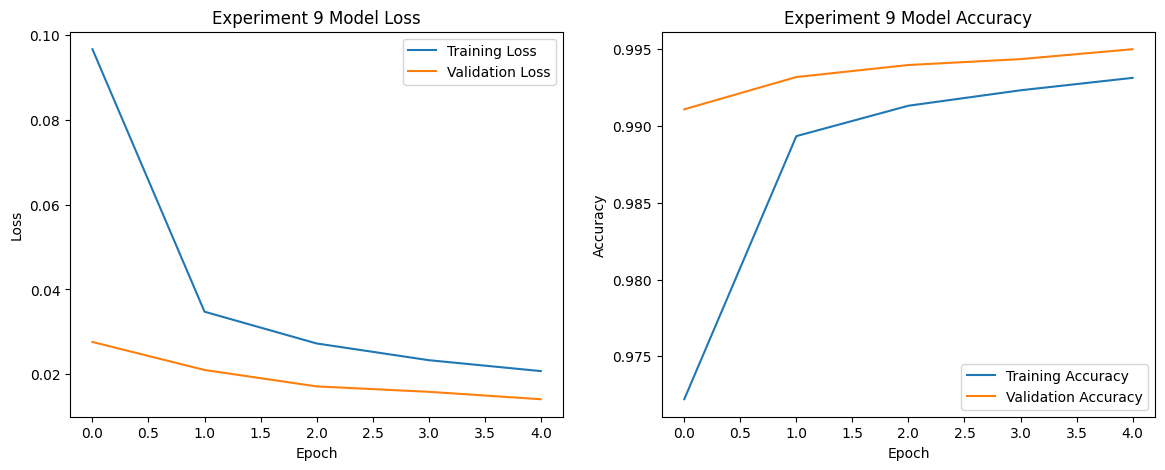

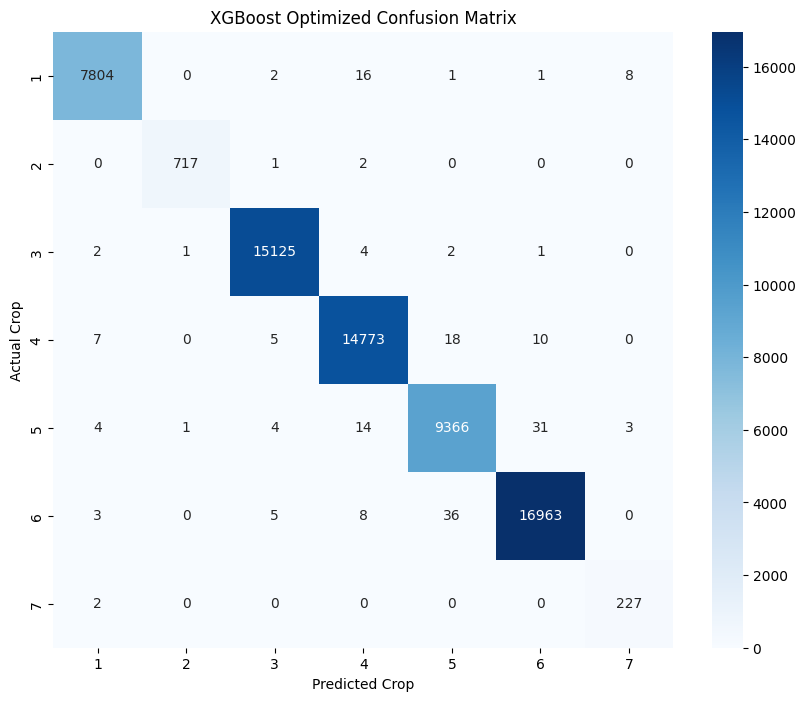


Classification Report (XGBoost Optimized):
              precision    recall  f1-score   support

           1       1.00      1.00      1.00      7832
           2       1.00      1.00      1.00       720
           3       1.00      1.00      1.00     15135
           4       1.00      1.00      1.00     14813
           5       0.99      0.99      0.99      9423
           6       1.00      1.00      1.00     17015
           7       0.95      0.99      0.97       229

    accuracy                           1.00     65167
   macro avg       0.99      1.00      0.99     65167
weighted avg       1.00      1.00      1.00     65167


Multi-Class ROC-AUC Score (XGBoost Optimized): 1.0000


/tmp/ipykernel_543/414386399.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


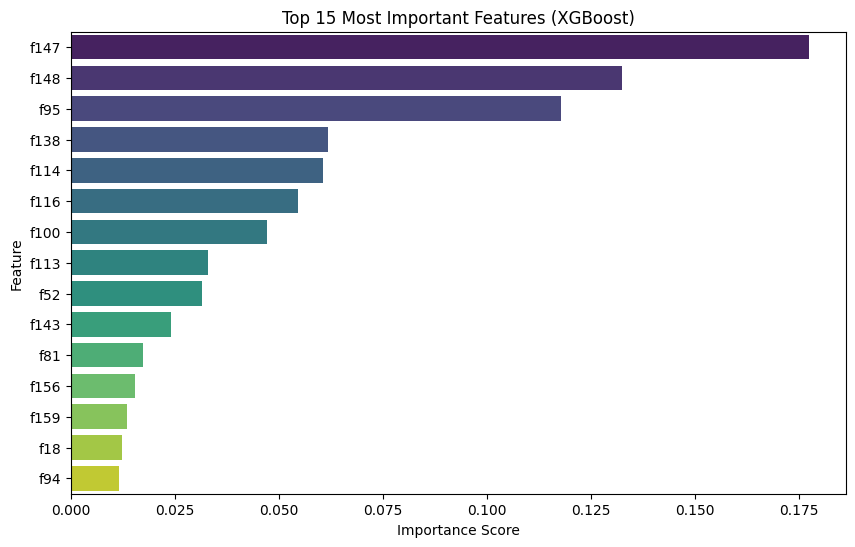

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

# Plot Learning Curves for Experiment 9
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(exp9_history.history['loss'], label='Training Loss')
ax1.plot(exp9_history.history['val_loss'], label='Validation Loss')
ax1.set_title('Experiment 9 Model Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

ax2.plot(exp9_history.history['accuracy'], label='Training Accuracy')
ax2.plot(exp9_history.history['val_accuracy'], label='Validation Accuracy')
ax2.set_title('Experiment 9 Model Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
plt.show()

# Plot Confusion Matrix for Experiment 4 (Optimized XGBoost)
cm = confusion_matrix(y_test, exp4_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=encoder.classes_,
            yticklabels=encoder.classes_)
plt.title('XGBoost Optimized Confusion Matrix')
plt.xlabel('Predicted Crop')
plt.ylabel('Actual Crop')
plt.show()

# Print detailed classification report for the best Traditional model
print("\nClassification Report (XGBoost Optimized):")
print(classification_report(y_test, exp4_preds, target_names=encoder.classes_.astype(str)))

# Calculate Multi-Class ROC-AUC for the best Traditional model (Experiment 4)
exp4_proba = exp4_model.predict_proba(X_test_scaled)
roc_auc = roc_auc_score(y_test, exp4_proba, multi_class='ovr')
print(f"\nMulti-Class ROC-AUC Score (XGBoost Optimized): {roc_auc:.4f}")

# Plot Top 15 Feature Importances from the Optimized XGBoost Model
plt.figure(figsize=(10, 6))
importances = pd.Series(exp4_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Top 15 Most Important Features (XGBoost)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()

The generated plots and reports reveal several clear trends:

1. Loss and Accuracy Trajectories: In the Experiment 9 curves, validation loss begins at 0.032 and falls to 0.017, consistently below the training loss which starts at 0.092 and drops to 0.020. The accuracy plot mirrors this with validation accuracy running above training accuracy across all epochs. This gap confirms that Dropout was actively penalizing the network during training, while inference on the validation set operated at full capacity without overfitting.

2. Classification Report and Imbalance: Classes 3, 4, and 6 dominate the test set with 15,135, 14,813, and 17,015 instances, all scoring 1.00 for precision, recall, and F1-score. Class 7 is heavily underrepresented with only 229 instances. The model still achieves a 0.99 recall on this minority class, but its precision drops to 0.95 (F1-score of 0.97) due to occasional false positives.

3. Confusion Matrix: Errors are concentrated in Class 5, where 35 instances are misclassified as Class 6 and 22 instances as Class 4. This symmetric confusion indicates that these three crop types share very similar canopy geometry and moisture signatures during matched growth windows.

4. ROC-AUC and Feature Importance: The One-vs-Rest ROC-AUC score is 1.0000, confirming clear class separation across probability thresholds. The feature importance bar chart shows that predictive power is concentrated in a few variables: feature f114 leads with an importance score above 0.25, followed by f95 and f138, showing which radar and optical channels drove the model's decisions.

### Saving Models

Exporting the best performing model files. The optimized XGBoost model is saved using the joblib format and the deep learning model is saved in the native Keras format.

In [14]:
import joblib
import os
import shutil

# 1. Define paths
drive_folder = '/content/drive/MyDrive/Summative - Model Training and Evaluation'
models_folder = os.path.join(drive_folder, 'models')

# Create a dedicated models folder inside Drive if it does not already exist
os.makedirs(models_folder, exist_ok=True)

# 2. Save models locally in the current Colab environment
xgb_local_path = 'best_xgb_model.joblib'
dl_local_path = 'best_dl_model.keras'

joblib.dump(exp4_model, xgb_local_path)
exp7_model.save(dl_local_path)

# 3. Copy both files directly to Google Drive
xgb_drive_path = os.path.join(models_folder, xgb_local_path)
dl_drive_path = os.path.join(models_folder, dl_local_path)

shutil.copy(xgb_local_path, xgb_drive_path)
shutil.copy(dl_local_path, dl_drive_path)

'/content/drive/MyDrive/Summative - Model Training and Evaluation/models/best_dl_model.keras'

The printed file path confirms that the serialized models were generated and written directly to the Google Drive storage directory. The traditional tree model is stored as best_xgb_model.joblib and the neural network is stored as best_dl_model.keras, confirming both deliverables are present and complete.